In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")
df = pd.read_csv("data/telco_clean.csv")

۱. نرخ کلی ریزش

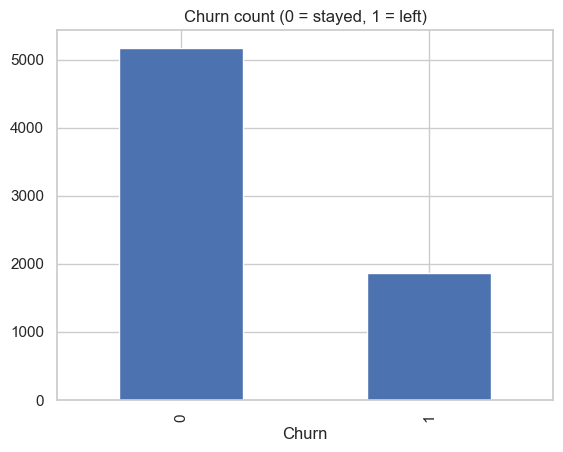

0.2653698707936959


In [4]:
df["Churn"].value_counts().plot(kind="bar")
plt.title("Churn count (0 = stayed, 1 = left)")
plt.show()
print(df["Churn"].mean())   # حدود 0.265

۲. ریزش بر اساس نوع قرارداد

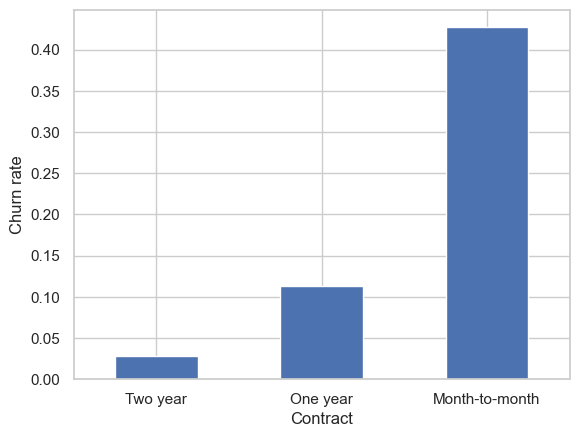

In [5]:
rate = df.groupby("Contract")["Churn"].mean().sort_values()
rate.plot(kind="bar")
plt.ylabel("Churn rate")
plt.xticks(rotation=0)
plt.show()

۳. ریزش بر اساس نوع اینترنت و روش پرداخت

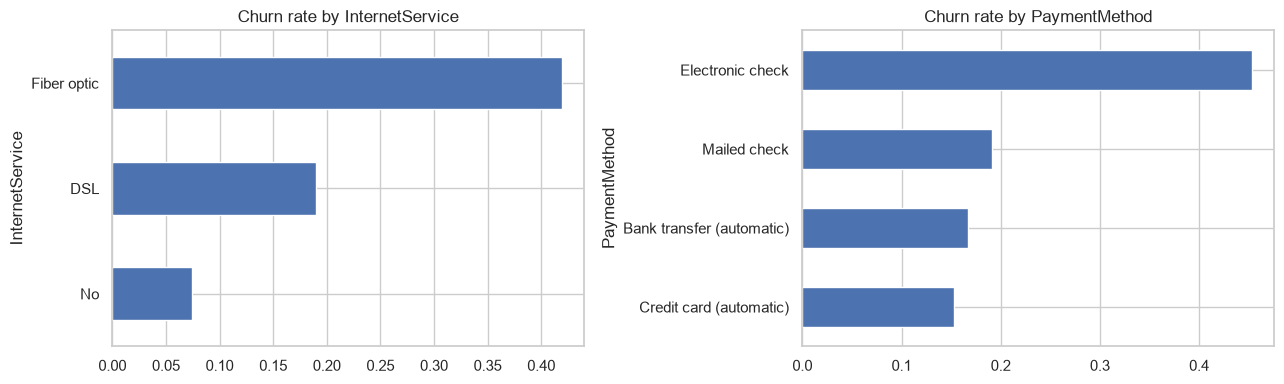

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["InternetService", "PaymentMethod"]):
    df.groupby(col)["Churn"].mean().sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Churn rate by {col}")
plt.tight_layout()
plt.show()

۴. اثر مدت عضویت (tenure) و هزینه‌ی ماهانه

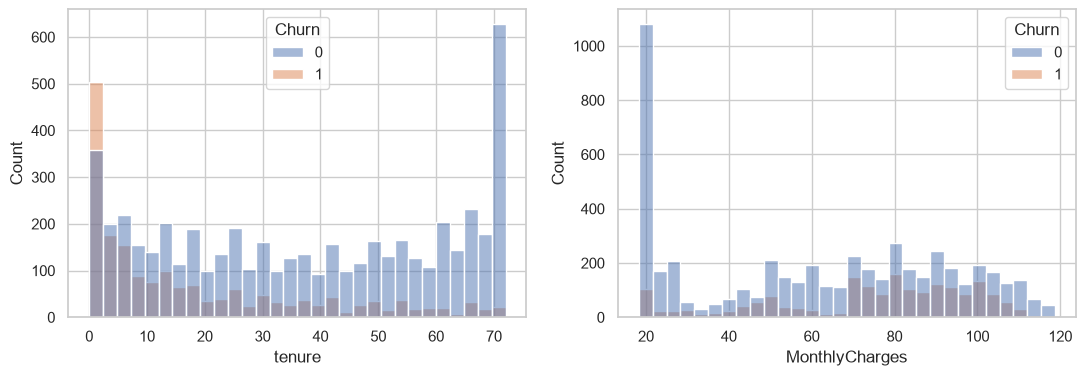

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, ax=axes[0])
sns.histplot(data=df, x="MonthlyCharges", hue="Churn", bins=30, ax=axes[1])
plt.show()

۵. اثر سرویس‌های جانبی (امنیت آنلاین، پشتیبانی فنی و...)

In [6]:
services = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport"]
df.groupby("TechSupport")["Churn"].mean()

TechSupport
0    0.311862
1    0.151663
Name: Churn, dtype: float64

۶. ماتریس همبستگی (فقط ستون‌های عددی)

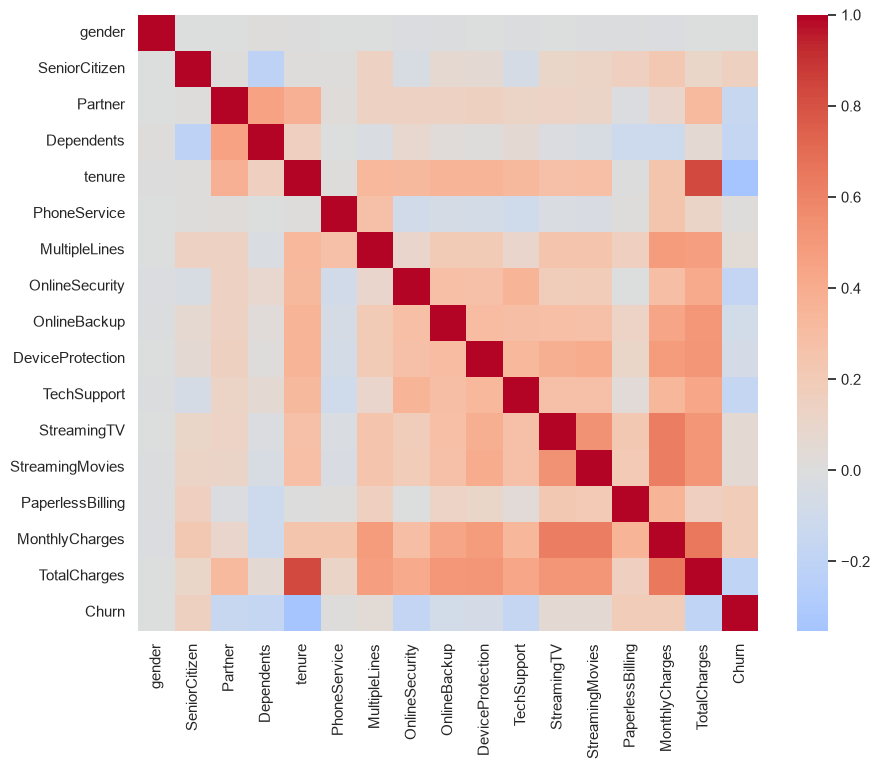

tenure             -0.352229
TotalCharges       -0.198324
OnlineSecurity     -0.171226
TechSupport        -0.164674
Dependents         -0.164221
Partner            -0.150448
OnlineBackup       -0.082255
DeviceProtection   -0.066160
gender             -0.008612
PhoneService        0.011942
MultipleLines       0.040102
StreamingMovies     0.061382
StreamingTV         0.063228
SeniorCitizen       0.150889
PaperlessBilling    0.191825
MonthlyCharges      0.193356
Churn               1.000000
Name: Churn, dtype: float64

In [7]:
num = df.select_dtypes(include="number")
plt.figure(figsize=(10, 8))
sns.heatmap(num.corr(), cmap="coolwarm", center=0)
plt.show()

num.corr()["Churn"].sort_values()

In [9]:
print("TechSupport (0=no, 1=yes):", df.groupby("TechSupport")["Churn"].mean().round(3).to_dict())
print("OnlineSecurity (0=no, 1=yes):", df.groupby("OnlineSecurity")["Churn"].mean().round(3).to_dict())
print("Mean by Churn:\n", df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1))
print("Tenure groups:", df.groupby("tenure_group", observed=True)["Churn"].mean().round(3).to_dict())

TechSupport (0=no, 1=yes): {0: 0.312, 1: 0.152}
OnlineSecurity (0=no, 1=yes): {0: 0.313, 1: 0.146}
Mean by Churn:
        tenure  MonthlyCharges
Churn                        
0        37.6            61.3
1        18.0            74.4
Tenure groups: {'0-6': 0.529, '7-12': 0.359, '13-24': 0.287, '25-48': 0.204, '49-72': 0.095}


## Key Findings from EDA | یافته‌های اصلی تحلیل اکتشافی

**1.ریزش کلی**
حدود ۲۶٫۵٪ مشتریان ریزش کرده‌اند، بنابراین داده نامتعادل است.

**2.  نوع قرارداد قوی‌ترین نشانه است**
ریزش مشتریان قرارداد ماهانه ۴۲٫۷٪ است، در مقابل ۱۱٫۳٪ برای قرارداد یک‌ساله و فقط ۲٫۸٪ برای دوساله (حدود ۱۵ برابر کمتر).

**3.مشتریان جدید بیشترین ریسک را دارند**
ریزش در ۶ ماه اول ۵۲٫۹٪ و در ماه‌های ۷ تا ۱۲ برابر ۳۵٫۹٪ است. با افزایش مدت عضویت کاهش می‌یابد و برای مشتریان با بیش از ۴ سال سابقه به ۹٫۵٪ می‌رسد. مشتریان ریزش‌کرده به‌طور میانگین ۱۸ ماه ماندند، در مقابل ۳۷٫۶ ماه برای مشتریان باقی‌مانده.

**4. نوع اینترنت**
مشتریان فیبر نوری ۴۱٫۹٪ ریزش دارند، خیلی بیشتر از DSL (۱۹٫۰٪) و مشتریان بدون اینترنت (۷٫۴٪).

**5. روش پرداخت**
کاربران چک الکترونیکی ۴۵٫۳٪ ریزش دارند، در حالی که پرداخت خودکار (انتقال بانکی و کارت اعتباری) فقط ۱۵ تا ۱۷٪ است.

**6.قیمت و خدمات پشتیبانی**
مشتریان ریزش‌کرده به‌طور میانگین ماهانه بیشتر می‌پردازند (۷۴٫۴ در مقابل ۶۱٫۳). مشتریان بدون پشتیبانی فنی ۳۱٫۲٪ ریزش دارند (در مقابل ۱۵٫۲٪ با پشتیبانی) و مشتریان بدون امنیت آنلاین ۳۱٫۳٪ (در مقابل ۱۴٫۶٪ با آن).

 ** نکته:** 
 این‌ها همبستگی هستند و علت و معلولِ اثبات‌شده نیستند. مثلاً چک الکترونیکی لزوماً باعث ریزش نمی‌شود و ممکن است فقط نشانه‌ی یک گروه خاص از مشتریان باشد.

###  نتیجه برای مرحله‌ی مدل‌سازی
-  از تقسیم داده‌ی stratified و معیارهایی فراتر از accuracy (مثل recall، F1 و ROC-AUC) استفاده می‌کنیم.
- انتظار داریم قرارداد، مدت عضویت و هزینه‌ی ماهانه ویژگی‌های مهمی باشند.